### MSM construction, validation, and analysis in FMRC space 

#### Example here: 15 bp DNA linker length

The FMRC algorithm follows the standard training protocol from [Flow Matching for Reaction Coordinates](https://github.com/Mingyuan00/Flow_Matching_for_RC).

In [1]:
from OpenCGChromatin import *
# OpenMM
import openmm as mm
from openmm import app, unit, Platform
# NumPy
import numpy as np
from numpy.random import multinomial
# MDTraj
import mdtraj as md
# Deeptime
from deeptime.decomposition import TICA
from deeptime.clustering import KMeans
from deeptime.data import double_well_2d
from deeptime.markov.msm import MaximumLikelihoodMSM, BayesianMSM
from deeptime.markov import TransitionCountEstimator
from deeptime.covariance import KoopmanWeightingEstimator
from deeptime.plots import plot_implied_timescales
from deeptime.plots.chapman_kolmogorov import plot_ck_test
from deeptime.util.validation import implied_timescales
# Matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import ListedColormap, BoundaryNorm, LogNorm, Normalize
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
# SciPy
from scipy.constants import Avogadro, Boltzmann, calorie_th
from scipy.spatial.distance import cdist
# NetworkX
import networkx as nx
# PyTorch
import torch
from torch import nn, optim, autograd
from torch import functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
# Standard library
from copy import deepcopy
import gc
import glob
import os
import pickle
# Plumed
import plumed

#Runtime setup
torch.cuda.empty_cache()
gc.collect()
os.environ["PLUMED_KERNEL"] = "/home/yc638/.conda/envs/py39/lib/libplumedKernel.so"
#if not hasattr(np, "alltrue"):
#    np.alltrue = np.all
device = "cuda" if torch.cuda.is_available() else "cpu"

class GaussianPrior(nn.Module):
    def __init__(self, mean_value, std_value):
        super().__init__()
        self.mean_ = nn.Parameter(torch.tensor(mean_value, dtype=torch.float32), requires_grad=False)
        self.std_ = nn.Parameter(torch.tensor(std_value, dtype=torch.float32), requires_grad=False)

    def forward(self, size):
        samples = self.mean_ + self.std_ * torch.randn(size).to(self.mean_.device)
        return samples

    def sample_like(self, x):
        size = x.size()
        samples = self.forward(size).to(x.device)
        return samples


class RCFlow(nn.Module):
    def __init__(self,input_size,latent_size,encoder_hidden_size,encode_state_label,hidden_size,hidden_depth,activation,sigma,
                 learning_rate,lr_decay,lr_decay_stepsize,val_frac,batch_size,batchnorm,n_epochs,device):
        super().__init__()
        
        # Neural network related
        self.input_size = input_size               # No. of features
        self.latent_size = latent_size
        self.encoder_hidden_size = encoder_hidden_size
        self.hidden_size = hidden_size
        self.hidden_depth = hidden_depth
        self.activation = activation
        self.batchnorm = batchnorm
        self.encode_state_label = encode_state_label
        self.sigma = sigma                         # the gaussian width of flow matching vector field sample, 
                                                   # serves as a regularization factor

        # Training related
        self.learning_rate = learning_rate
        self.lr_decay = lr_decay
        self.lr_decay_stepsize = lr_decay_stepsize
        self.val_frac = val_frac
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.device = device

        # Cached attributes
        self.encoder = None
        self.L_vector_field = None
        self.D_vector_field = None
        self.optimizer = None
        self.scheduler = None
        self.train_loss = None
        self.validation_loss = None
        
        #####
        
        ### Encoder x --> r(x) as a feed forward nn
        self.encoder = []
        # first layer
        self.encoder.append(nn.Linear(self.input_size,self.encoder_hidden_size))
        # Insert dropout/batchnorm here
        # Activation
        self.encoder.append(self.activation)
        if self.batchnorm == True:
            self.encoder.append(nn.BatchNorm1d(self.encoder_hidden_size))
        # middle layers
        for i in range(self.hidden_depth-1):
            self.encoder.append(nn.Linear(self.encoder_hidden_size,self.encoder_hidden_size))
            self.encoder.append(self.activation)
            if self.batchnorm == True:
                self.encoder.append(nn.BatchNorm1d(self.encoder_hidden_size))
        
        # final output layer
        self.encoder.append(nn.Linear(self.encoder_hidden_size,self.latent_size))
        
        if self.encode_state_label == True:
            self.encoder.append(nn.Softmax())
            
        self.encoder = nn.Sequential(*self.encoder).to(self.device)

        #####

        ### nn that represents the lumpability vector field u(r(x),y,t)
        self.L_vector_field = []
        L_input_size = self.latent_size + self.input_size + 1
        
        # first layer
        self.L_vector_field.append(nn.Linear(L_input_size,self.hidden_size))
        self.L_vector_field.append(self.activation)
        if self.batchnorm == True:
            self.L_vector_field.append(nn.BatchNorm1d(self.hidden_size))
        # middle layers
        for i in range(self.hidden_depth-1):
            self.L_vector_field.append(nn.Linear(self.hidden_size,self.hidden_size))
            self.L_vector_field.append(self.activation)
            if self.batchnorm == True:
                self.L_vector_field.append(nn.BatchNorm1d(self.hidden_size))
        # final output layer
        self.L_vector_field.append(nn.Linear(self.hidden_size,self.input_size))
        self.L_vector_field = nn.Sequential(*self.L_vector_field).to(self.device)

        #####
        
        ### nn that represents the decomposibility vector field u(r(y),x,t)
        self.D_vector_field = []
        
        D_input_size = self.latent_size + self.input_size + 1
        
        # first layer
        self.D_vector_field.append(nn.Linear(D_input_size,self.hidden_size))
        self.D_vector_field.append(self.activation)
        if self.batchnorm == True:
            self.D_vector_field.append(nn.BatchNorm1d(self.hidden_size))
        # middle layers
        for i in range(self.hidden_depth-1):
            self.D_vector_field.append(nn.Linear(self.hidden_size,self.hidden_size))
            self.D_vector_field.append(self.activation)
            if self.batchnorm == True:
                self.D_vector_field.append(nn.BatchNorm1d(self.hidden_size))
        # final output layer
        self.D_vector_field.append(nn.Linear(self.hidden_size,self.input_size))
        self.D_vector_field = nn.Sequential(*self.D_vector_field).to(self.device)

        #####
        
    def encode(self, x):
        # Here, x is the variable to be encoded i.e. for lumpability x:= x for decomposibility x:= y
        # encode x --> r:=r(x)
        r = self.encoder(x)
        return r

    def sample_from_prior(self, x):
        # Sample x/y (D_loss/L_loss) from prior, prior_sample should have shape (batch_size,input_size)
        # Since this is just a gaussian with mean & s.t.d from all data, x/y can share the same prior
        prior_sample = self.prior.sample_like(x)
        return prior_sample

    def sample_t(self, x):
        # Sample t = [t_1,...t_B], t should have shape (batch_size,)
        t = torch.rand_like(x[:, :1])
        return t

    def sample_x_t(self, x, t, prior_sample):
        # Sample x_t/y_t, the 'location' of x/y after 'time' t in the vector field
        x_t = x * t + (1 - t) * prior_sample + torch.randn_like(x) * self.sigma
        return x_t

    def data_vector_field(self, x, prior_sample):
        # Calculate v_t, the 'data vector field' that we want to match our 'neural network vector field' with
        v_t = x - prior_sample
        return v_t

    def L_loss(self, x, y, t, rx=None):
        # Step 1: encode x --> r(x)
        if rx == None:
            rx = self.encode(x)
        
        # Step 2: sample y from prior
        prior_y = self.sample_from_prior(y)
        
        # Step 3: sample y_t, y at time t in the vector field
        y_t = self.sample_x_t(y, t, prior_y)

        # Step 4: compute 'data vector field'
        v_t = self.data_vector_field(y, prior_y)

        # Step 5: compute 'nn vector field'
        u_input = torch.cat((rx, y_t, t), dim=-1)
        # so that u_t is a function of rx,y_t,t only i.e. rx contains nearly same information as x
        u_t = self.L_vector_field(u_input)
        
        # Step 6: compute flow matching loss
        L_loss = torch.mean(torch.sum((u_t - v_t) ** 2, -1))
        
        return L_loss

    def D_loss(self, x, y, t, ry=None):
        # Step 1: encode y --> r(y)
        if ry == None:
            ry = self.encode(y)
        
        # Step 2: sample x from prior
        prior_x = self.sample_from_prior(x)
        
        # Step 3: sample x_t, x at time t in the vector field
        x_t = self.sample_x_t(x, t, prior_x)

        # Step 4: compute 'data vector field'
        v_t = self.data_vector_field(x, prior_x)

        # Step 5: compute 'nn vector field'
        u_input = torch.cat((ry, x_t, t), dim=-1)
        # so that u_t is a function of rx,y_t,t only i.e. rx contains nearly same information as x
        u_t = self.D_vector_field(u_input)
        
        # Step 6: compute flow matching loss
        D_loss = torch.mean(torch.sum((u_t - v_t) ** 2, -1))
        
        return D_loss

    def fit(self, data, lagtime):
        # NB: usually we use tica_output as data
        # Initialize the gaussian prior
        prior_mean = np.mean(np.concatenate(data), axis=0)
        prior_sigma = np.std(np.concatenate(data), axis=0)
        self.prior = GaussianPrior(prior_mean, prior_sigma).to(self.device)

        # Create time-lagged dataset: this outputs a 3d numpy array with shape (no_frame,2,no_features)
        # the second dimension represents the time-lagged pairs X_t,X_t+tau
        dataset = create_timelagged_dataset(data, lagtime)

        # Create training set and validation set
        n_pairs = len(dataset)
        train_size = int((1-self.val_frac)*n_pairs)
        val_size = n_pairs - train_size
        train_data, val_data = random_split(dataset, [train_size, val_size])
        train_loader = torch.utils.data.DataLoader(train_data, batch_size=self.batch_size, shuffle=True)
        val_loader = torch.utils.data.DataLoader(val_data, batch_size=self.batch_size)

        # Training
        self.optimizer = optim.Adam(self.parameters(), lr=self.learning_rate)
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=self.lr_decay_stepsize, gamma=self.lr_decay)
        
        train_loss = []
        validation_loss = []
        
        with torch.autograd.set_detect_anomaly(True):
            for epoch in range(1, n_epochs + 1):
                train_loss_epoch = []
                validation_loss_epoch = []
                
                # Training
                for minibatch_data in train_loader:
                    # Prepare x and y, should both in shape (batchsize,no_features)
                    x = minibatch_data[:,0,:].to(self.device)
                    y = minibatch_data[:,1,:].to(self.device)
                    # Sample t
                    t = self.sample_t(x)
                    # Compute losses
                    L_loss = self.L_loss(x,y,t)
                    D_loss = self.D_loss(x,y,t)
                    loss = L_loss + D_loss
                    # back propagation
                    self.optimizer.zero_grad()
                    loss.backward()
                    self.optimizer.step()
                    # Record current minibatch loss
                    train_loss_epoch.append(loss.item())
                train_loss_epoch = np.mean(train_loss_epoch)
                train_loss.append(train_loss_epoch)
                
                # learning rate decay
                self.scheduler.step()

                # Validation
                with torch.no_grad():
                    for minibatch_data in val_loader:
                        # Prepare x and y, should both in shape (batchsize,no_features)
                        x = minibatch_data[:,0,:].to(self.device)
                        y = minibatch_data[:,1,:].to(self.device)
                        # Sample t
                        t = self.sample_t(x)
                        # Compute losses
                        L_loss = self.L_loss(x,y,t)
                        D_loss = self.D_loss(x,y,t)
                        loss = L_loss + D_loss
                        # Record current minibatch loss
                        validation_loss_epoch.append(loss.item())
                    validation_loss_epoch = np.mean(validation_loss_epoch)
                    validation_loss.append(validation_loss_epoch)

                print('Epoch {}: Train loss = {:.4f}, Validation loss = {:.4f}'.format(epoch,train_loss_epoch,validation_loss_epoch))

        self.train_loss = train_loss
        self.validation_loss = validation_loss
                
        return None

    def transform(self, data_concat):
        r = self.encode(torch.tensor(data_concat, dtype=torch.float32).to(self.device)).cpu().detach().numpy()
        return r

    def save_model(self, filepath):
        torch.save(self, filepath)
        return None

    def plot_loss(self, sim_idx):
        fig, ax = plt.subplots()
        ax.plot(self.train_loss, label='train')
        ax.plot(self.validation_loss, label='validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        plt.legend()
        plt.savefig('round{sim_idx}_rcflow_loss.png'.format(sim_idx=sim_idx-1), dpi=600)

# We want to organize time-series trajectories of TICA eigenvectors into time-lagged pairs according to lagtime
# i.e. tica_output + tica_output_supp --> data in RCflow, should be inshape (no_time_lagged_pairs, no_features * 2)
def create_timelagged_dataset(tica_output, lagtime):
    timelagged_dataset = []
    tica_data = list(tica_output)
    for tica_data_i in tica_data:
        for i in range(tica_data_i.shape[0]-lagtime):
            lagged_pair_i = np.vstack([tica_data_i[i], tica_data_i[i+lagtime]])
            lagged_pair_i = np.array(lagged_pair_i)
            timelagged_dataset.append(lagged_pair_i)
    timelagged_dataset = torch.tensor(np.array(timelagged_dataset), dtype=torch.float32)
    return timelagged_dataset

def minmax_normalization(data, axis=0):
    data_max = data.max(axis=0)
    data_min = data.min(axis=0)
    normalized_data = (data - data_min) / (data_max - data_min)
    return normalized_data

def run_TICA(data, lagtime, dim=None, var_cutoff=None):
    tica = TICA(lagtime=lagtime, dim=dim, var_cutoff=var_cutoff)
    tica = tica.fit(data).fetch_model()
    tica_output = tica.transform(data)
    return tica, tica_output

##### Process PLUMED-generated features

In [2]:
def read_features_indices(prefix_dir, start_idx, end_idx):
    data = []
    for i in range(start_idx, end_idx + 1):
        path = os.path.join(prefix_dir, f"COLVAR_{i}")
        try:
            df = plumed.read_as_pandas(path)
        except FileNotFoundError:
            print(f"[WARN] {path} not found, skipping")
            continue

        if "time" in df.columns:
            df = df.drop(columns=["time"])
        for col in list(df.columns):
            if col.startswith(("bend", "psi", "angle")):
                df = df.drop(columns=[col])
        data.append(df.to_numpy(dtype=np.float32))

    return data

start_idx=1
end_idx=920
colvar = '/scratch/yc638/bsc/NEW/15/CV_new'
data = read_features_indices(colvar, start_idx, end_idx)

+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/yc638/.conda/envs/py39/lib/libplumedKernel.so" +++
/tmp/ipykernel_586307/636866823.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = plumed.read_as_pandas(path)
+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/yc638/.conda/envs/py39/lib/libplumedKernel.so" +++
/tmp/ipykernel_586307/636866823.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = plumed.read_as_pandas(path)
+++ Loading the PLUMED kernel runtime +++
+++ PLUMED_KERNEL="/home/yc638/.conda/envs/py39/lib/libplumedKernel.so" +++
/tmp/ipykernel_586307/636866823.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = plumed.read_as_pandas(path)
+

In [3]:
len(data),(data[0].shape)

(920, (500, 2720))

#### FMRC training parameters

In [4]:
import math
import json
from pathlib import Path
dim = 100
var_cutoff = None
data=data
# FMRC training hyperparamters
rcflow_lagtimes = [250]
latent_size = 2                                
encoder_hidden_size = 512
encode_state_label = False
hidden_size = 512
hidden_depth = 3
activation = nn.ReLU()
sigma = 0.001
learning_rate = 0.001
lr_decay = 0.3
lr_decay_stepsize = 50
val_frac = 0.1
batch_size = 512
batchnorm = False
n_epochs = 100
device = 'cuda'
batchsize_transform = 1024
normalized_r = []
MODEL_DIR = Path("/scratch/yc638/NEW/15")
FIG_DIR = MODEL_DIR / "figure"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

RCFlow(
  (activation): ReLU()
  (encoder): Sequential(
    (0): Linear(in_features=100, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=2, bias=True)
  )
  (L_vector_field): Sequential(
    (0): Linear(in_features=103, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=100, bias=True)
  )
  (D_vector_field): Sequential(
    (0): Linear(in_features=103, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=10

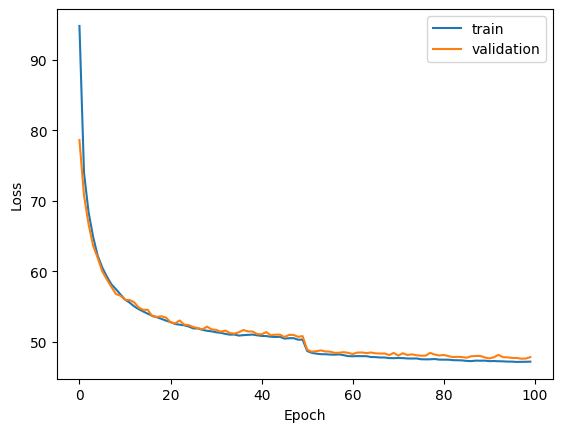

In [5]:
for i, rcflow_lagtime in enumerate(rcflow_lagtimes, start=1):
    tica,tica_output = run_TICA(data,rcflow_lagtime,dim,var_cutoff)
    input_size = tica_output.shape[2]
    tica_output_concat = np.concatenate(tica_output)
    n_samples, feature_dim = int(tica_output_concat.shape[0]), int(tica_output_concat.shape[1])
    no_iteration = math.ceil(n_samples / batchsize_transform)
    rcflow = RCFlow(input_size,latent_size,encoder_hidden_size,encode_state_label,hidden_size,hidden_depth,activation,sigma,
                    learning_rate,lr_decay,lr_decay_stepsize,val_frac,batch_size,batchnorm,n_epochs,device)
    print(rcflow)
    rcflow.fit(tica_output,rcflow_lagtime)
    
    rcflow.plot_loss(sim_idx=i)
    (FIG_DIR / f"loss_curve_{i}.png").resolve()
    plt.savefig(FIG_DIR / f"input_dim{dim}_loss_curve_{i}_lag{rcflow_lagtime}.png", dpi=600)

    model_path = MODEL_DIR / f"input_dim{dim}_rcflow_lag{rcflow_lagtime}-512hidden-latent2_final.pt"
    rcflow.save_model(str(model_path))
    no_iteration = tica_output_concat.shape[0]//batchsize_transform + 1
    # Transform into RC space
    r = []
    for j in range(no_iteration):
        r_j = rcflow.transform(tica_output_concat[j*batchsize_transform:(j+1)*batchsize_transform])
        r.append(r_j)
    r = np.concatenate(r)
    # Normalize r for better clustering result
    normalized_r_i = minmax_normalization(r,axis=0)
    normalized_r.append(normalized_r_i)
    

In [6]:
normalized_r[0].shape

(460000, 2)

#### Data distribution in 2D FMRC space

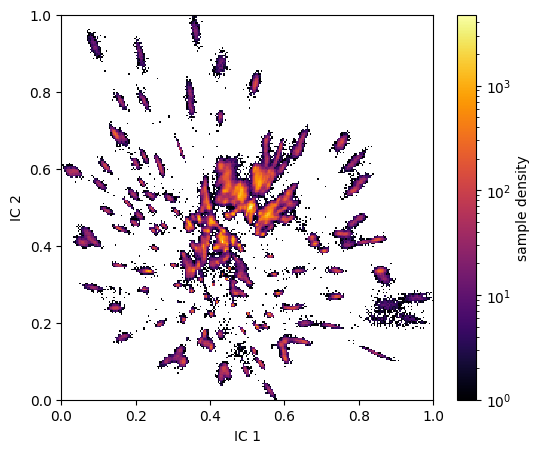

In [7]:
vis_tic = (0, 1)
X= normalized_r[0]
fmrc_dens_kwargs = dict(
    bins=250,
    range=[
        (X[:,vis_tic[0]].min(), X[:,vis_tic[0]].max()),
        (X[:,vis_tic[1]].min(), X[:,vis_tic[1]].max())
    ],
    norm=LogNorm(),        
    cmap="inferno"   
)

plt.figure(figsize=(6, 5))

plt.hist2d(
    X[:, vis_tic[0]],
    X[:, vis_tic[1]],
    **fmrc_dens_kwargs
)
plt.colorbar(label="sample density")
plt.xlabel(f"IC {vis_tic[0] + 1}")
plt.ylabel(f"IC {vis_tic[1] + 1}")
plt.show()

#### Microstate clustering in FMRC space

In [ ]:
from deeptime.clustering import MiniBatchKMeans
def run_kmeans(tica_output, n_microstates, n_jobs):
    minibatch_kmeans = MiniBatchKMeans(n_clusters=n_microstates, batch_size=10000, max_iter=100, init_strategy='kmeans++', n_jobs=n_jobs)
    microstates = minibatch_kmeans.fit(tica_output).fetch_model()
    cluster_centers = microstates.cluster_centers
    assignments = microstates.transform(tica_output)
    return assignments, cluster_centers

assignments, cluster_centers = run_kmeans(normalized_r[0], n_microstates=1500, n_jobs=32)

In [17]:
assignments.shape

(460000,)

#### Implied timescales (ITS) analysis

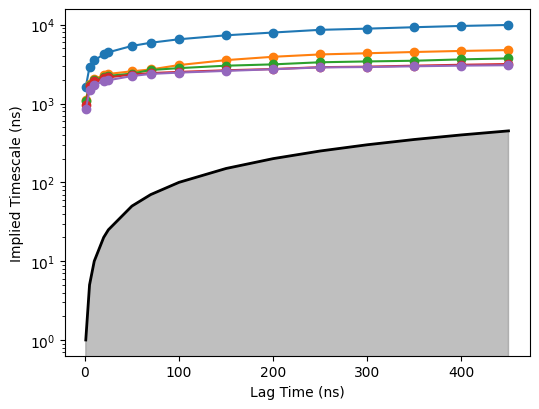

In [18]:
n_its = 5
its_lagtimes = [1, 5, 10, 20, 25, 50, 70, 100, 150, 200, 250, 300, 350, 400, 450]
models = []
for its_lagtime in its_lagtimes:
    counts = TransitionCountEstimator(lagtime=its_lagtime, count_mode='sliding').fit_fetch(assignments)
    models.append(MaximumLikelihoodMSM().fit_fetch(counts))
its_data_i = implied_timescales(models)
ns_per_step = 1
fig, ax = plt.subplots(figsize=(6,4.5))

for i in range(n_its):
    ax.plot(its_data_i.lagtimes * ns_per_step, its_data_i.timescales_for_process(i) * ns_per_step, marker='o')
ax.plot(its_data_i.lagtimes * ns_per_step, its_data_i.lagtimes * ns_per_step, linewidth=2, color='black')
ax.fill_between(its_data_i.lagtimes * ns_per_step, np.full((its_data_i.n_lagtimes,), fill_value=ax.get_ylim()[0]), its_data_i.lagtimes * ns_per_step,
                alpha=0.5, color='grey')
ax.set_yscale('log')
ax.set_xlabel('Lag Time (ns)')
ax.set_ylabel('Implied Timescale (ns)')
plt.show()

#### MSM construction

In [19]:
ML_MSM_lagtime = 250
msm = MaximumLikelihoodMSM().fit_fetch(TransitionCountEstimator(lagtime=ML_MSM_lagtime, count_mode='sliding').fit_fetch(assignments))

In [20]:
msm.transition_matrix.shape

(1500, 1500)

#### Save the microstate assignments and MSM stationary probabilities for later free-energy landscape projection.

In [ ]:
np.save(f"input_dim{dim}_msm{ML_MSM_lagtime}_trajs_fmrc_250.npy", assignments)
pi = msm.stationary_distribution
np.savetxt(f"input_dim{dim}_msm{ML_MSM_lagtime}_pi_fmrc_250.txt", pi)

#### Check the CV columns onto which you want to project the free energy landscape.

In [22]:
colvar = '/scratch/yc638/bsc/NEW/15/CV_new'
colvar1 = os.path.join(colvar, "COLVAR_1")
with open(colvar1) as f:
    for line in f:
        if line.startswith("#! FIELDS"):
            tokens = line.strip().split()[2:] 
            break
    else:
        raise RuntimeError("No '#! FIELDS' line found in COLVAR_1")
fields = [t for t in tokens if t != "time"]
feature_list = []
for feat in fields:
    if feat.startswith(("phi", "bend", "angle")):
        feature_list.extend([f"sin_{feat}", f"cos_{feat}"])
    else:
        feature_list.append(feat)

i13 = feature_list.index("dist_core1_3")
i24 = feature_list.index("dist_core2_4")
print("d13_COM -> column", i13)
print("d24_COM -> column", i24)

d13_COM -> column 1
d24_COM -> column 4


5.419855 40.34211
5.570827 40.325638


/tmp/ipykernel_586307/3623832224.py:31: UserWarning: The following kwargs were not used by contour: 'edgecolors'
  cf = ax.contourf(


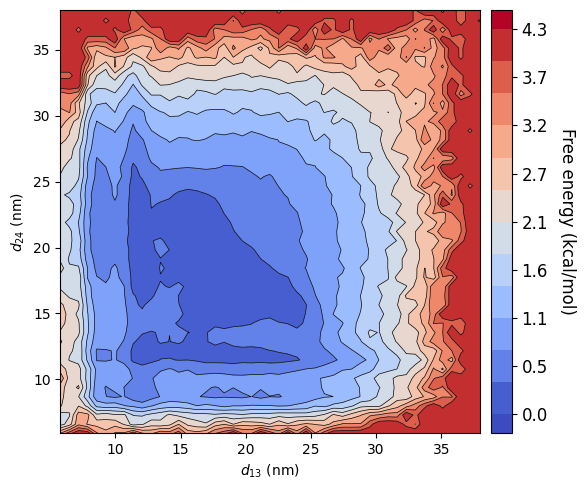

In [23]:
x = np.concatenate(data, axis=0)
i13, i24 = 1, 4
d13 = x[:, i13]
d24 = x[:, i24]
print(min(d13), max(d13))
print(min(d24), max(d24))

# Load MSM outputs
pi     = np.loadtxt(f"input_dim{dim}_msm{ML_MSM_lagtime}_pi_fmrc_250.txt")
ct_flat = assignments.flatten()
counts  = np.bincount(ct_flat, minlength=len(pi))
weights = pi[ct_flat] / counts[ct_flat]

# Build weighted 2D histogram 
THERMO = 1e-3 * Boltzmann * Avogadro / calorie_th
T = 300
H, xedges, yedges = np.histogram2d(d13, d24, bins=50, weights=weights)
H[H == 0] = H[H > 0].min()
F = -THERMO * T * np.log(H)           
F -= F.min()  

#grid the bin centers
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc)

fig, ax = plt.subplots(figsize=(6, 5)) 
vmax=F.max()
levels = np.linspace(0, vmax, 13)
ticks = np.linspace(0, vmax, 9)
cf = ax.contourf(
    Xc,
    Yc,
    F.T,
    levels=levels,
    cmap="coolwarm", 
    vmin=0.,
    vmax=vmax,
    extend='both',
    antialiased=True,      
    edgecolors='face'
)
cs = ax.contour(
    Xc,
    Yc,
    F.T,
    levels=levels,
    colors="k",
    linewidths=0.5
)

ax.set_xlabel(r"$d_{13}$ (nm)")
ax.set_ylabel(r"$d_{24}$ (nm)")
ax.set_xlim(right=38.)
ax.set_ylim(top=38.)
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)

# Add a tight colorbar with its own label
cbar = fig.colorbar(cf, ax=ax, extendrect=True,pad=0.02, ticks=ticks)
cbar.set_label("Free energy (kcal/mol)", rotation=270, labelpad=20, fontsize=12)
cbar.ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.1f"))
cbar.ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()


#### Chapman-Kolmogorov (CK) test

/home/yc638/.conda/envs/py39/lib/python3.9/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/yc638/.conda/envs/py39/lib/python3.9/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


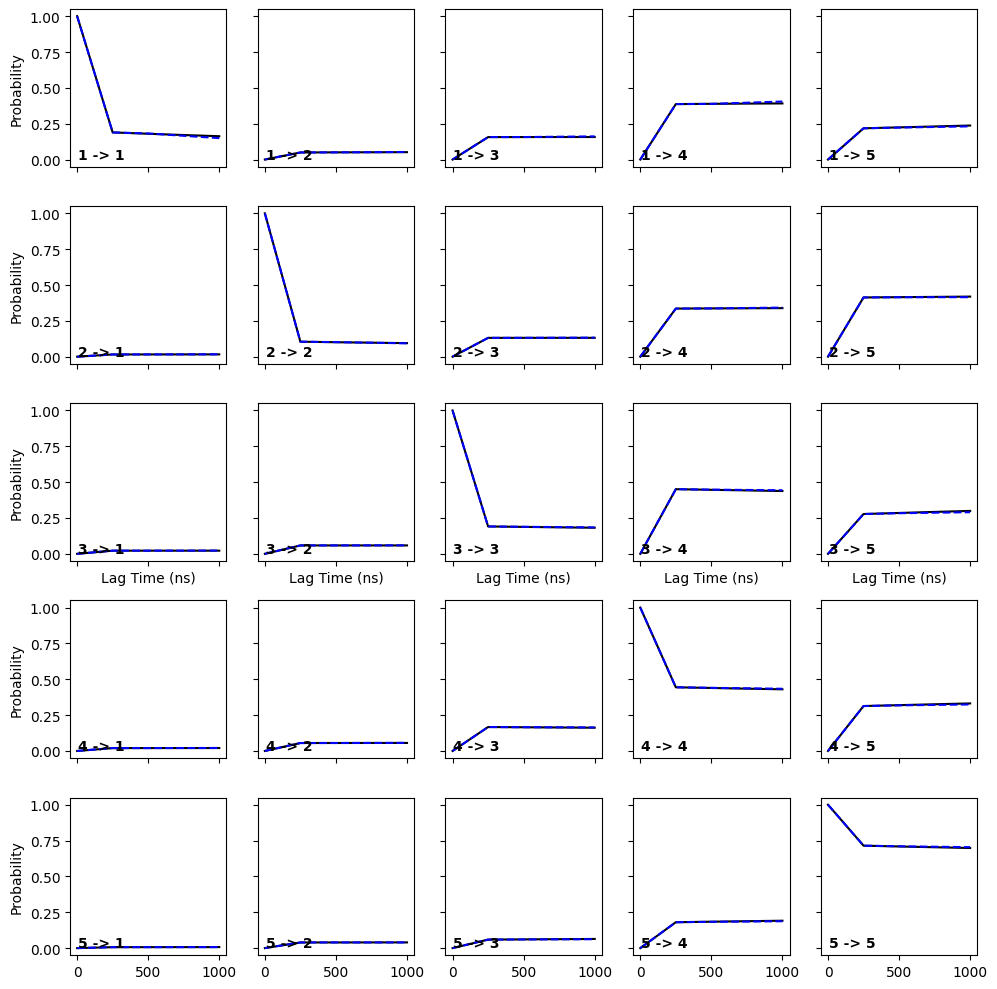

In [24]:
n_metastable_sets = 5
# Chapman-Kolmogorov test lagtimes=k*MSM lagtime
ck_lagtimes = [250, 500, 750, 1000]
ns_per_step = 1
models = []
for ck_lagtime in ck_lagtimes:
    counts = TransitionCountEstimator(lagtime=ck_lagtime, count_mode='sliding').fit_fetch(assignments)
    models.append(MaximumLikelihoodMSM().fit_fetch(counts))
ck_test = msm.ck_test(models,n_metastable_sets=n_metastable_sets)
fig,ax = plt.subplots(nrows=ck_test.n_components,ncols=ck_test.n_components,sharex=True,sharey=True,figsize=(10,10))
for i in range(ck_test.n_components):
    for j in range(ck_test.n_components):
        ax[i,j].plot(ck_test.lagtimes * ns_per_step, ck_test.predictions[:,i,j],color='black')
        ax[i,j].plot(ck_test.lagtimes * ns_per_step, ck_test.estimates[:,i,j] ,color='blue',linestyle='dashed')
        if i == 2:
            ax[i,j].set_xlabel('Lag Time (ns)')
        if j == 0:
            ax[i,j].set_ylabel('Probability')
        ax[i,j].text(0.05, 0.05, str(i + 1) + ' -> ' + str(j + 1), transform=ax[i,j].transAxes, weight='bold')
plt.tight_layout()
plt.show()

#### PCCA+ Clustering

In [28]:
pcca = msm.pcca(n_metastable_sets=5)

#### Visualise transition fluxes between macrostates

[saved] mfpt_matrix_ns.csv
[saved] mfpt_edgelist.csv


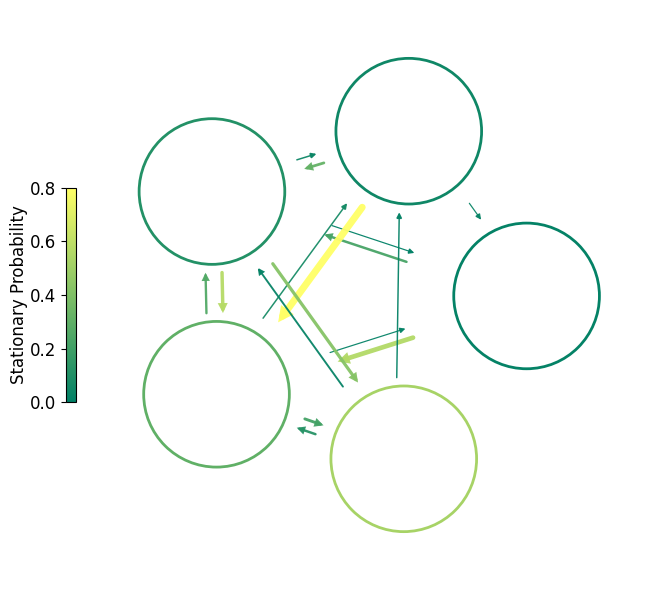

In [29]:
# FIGURE FORMAT
msm_lagtime = ML_MSM_lagtime
time_unit   = "ns"
layout_kind = "kamada"

PROB_THRESHOLD   = 1e-4
FLUX_THRESHOLD   = 1e-4
MFPT_MAX         = None
TOPK_PER_SOURCE  = None

NODE_SIZE        = 11000.0
NODE_EDGE_LW     = 2
TEXT_FS          = 9

ARROW_LW_MIN, ARROW_LW_MAX = 0.8, 5.0
PARALLEL_SEP     = 0.05
PAD_FRAC         = 0.02
JITTER_FRAC      = 0.02
FIGSIZE          = (8, 6)
STRUCTURE_SPACE_PX = 200

# MACROSTATE DATA
T_cg  = np.asarray(pcca.coarse_grained_transition_matrix, float)
pi_cg = np.asarray(pcca.coarse_grained_stationary_probability, float)
k     = T_cg.shape[0]
labels  = [f"S{i+1}" for i in range(k)]
pi_pct  = 100.0 * (pi_cg / pi_cg.sum())

cmap_node  = cm.summer
norm_node  = Normalize(vmin=0.0, vmax=0.8)
node_edge_colors = [cmap_node(norm_node(pi)) for pi in pi_cg]

# HELPERS
def edge_passes(i, j):
    if i == j:
        return False
    if PROB_THRESHOLD is not None and T_cg[i, j] <= PROB_THRESHOLD:
        return False
    if FLUX_THRESHOLD is not None and (pi_cg[i] * T_cg[i, j]) <= FLUX_THRESHOLD:
        return False
    if MFPT_MAX is not None:
        tij = MFPT_time[i, j]
        if not (np.isfinite(tij) and tij > 0) or tij > MFPT_MAX:
            return False
    return True

def mfpt_to_target(T, j):
    n = T.shape[0]
    mask = np.ones(n, dtype=bool)
    mask[j] = False
    A = np.eye(n - 1) - T[np.ix_(mask, mask)]
    b = np.ones(n - 1)
    m = np.linalg.solve(A, b)
    out = np.zeros(n)
    out[mask] = m
    out[j] = 0.0
    return out

def mfpt_matrix(T):
    n = T.shape[0]
    M = np.zeros((n, n))
    for j in range(n):
        M[:, j] = mfpt_to_target(T, j)
    return M

def pixels_to_data_delta(ax, dx_px=0.0, dy_px=0.0, anchor=None):
    """Convert a pixel offset into a data-space delta relative to *anchor*
    (defaults to axes centre)."""
    if anchor is None:
        anchor = (
            0.5 * (ax.get_xlim()[0] + ax.get_xlim()[1]),
            0.5 * (ax.get_ylim()[0] + ax.get_ylim()[1]),
        )
    p0 = ax.transData.transform(anchor)
    d1 = ax.transData.inverted().transform((p0[0] + dx_px, p0[1] + dy_px))
    return abs(d1[0] - anchor[0]), abs(d1[1] - anchor[1])

def _make_colorbar(ax, cmap, norm, label, location="left", shrink=0.4, n_ticks=5, **kwargs):
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    ticks = np.linspace(norm.vmin, norm.vmax, n_ticks)
    rotation = 90 if location in ("left", "right") else 0
    cbar = plt.colorbar(
        sm, ax=ax, fraction=0.015, pad=0.02,
        location=location, shrink=shrink, ticks=ticks, **kwargs,
    )
    cbar.set_label(label, rotation=rotation, labelpad=1.2, fontsize=12)
    cbar.ax.tick_params(labelsize=12)
    return cbar

def _shorten(D1, D2, r_pix_val, u_hat):
    """Pull arrow tips/backs slightly inside node edges."""
    dist = np.linalg.norm(D2 - D1)
    if dist == 0:
        return D1, D2
    base = min(0.8 * r_pix_val, max(0.0, 0.45 * dist))
    return D1 + u_hat * base, D2 - u_hat * base


def _draw_arrow_pixels(ax, Pstart_pix, Pend_pix, lw=1.0, color="gray"):
    Q1 = ax.transData.inverted().transform(Pstart_pix)
    Q2 = ax.transData.inverted().transform(Pend_pix)
    arr = FancyArrowPatch(
        Q1, Q2, arrowstyle="-|>", mutation_scale=8,
        linewidth=lw, color=color, alpha=0.95,
        connectionstyle="arc3,rad=0",
        capstyle="round", joinstyle="miter",
        shrinkA=0, shrinkB=0, zorder=0.3, transform=ax.transData,
    )
    ax.add_patch(arr)


def _draw_directed_edge(ax, src, dst, sign, node_pos, T_cg, MFPT_time,
                        r_pix, u_pair, nrm_pair,
                        cmap_arrow, norm_arrow, max_speed):
    if not edge_passes(src, dst):
        return
    Ds = ax.transData.transform(np.array(node_pos[src]))
    Dd = ax.transData.transform(np.array(node_pos[dst]))
    u  = sign * u_pair
    D1, D2 = _shorten(Ds, Dd, r_pix, u)
    D1 += sign * nrm_pair * (PARALLEL_SEP * r_pix)
    D2 += sign * nrm_pair * (PARALLEL_SEP * r_pix)
    tij = MFPT_time[src, dst]
    s   = (1.0 / tij) / max_speed
    lw  = ARROW_LW_MIN + (ARROW_LW_MAX - ARROW_LW_MIN) * s
    _draw_arrow_pixels(ax, D1, D2, lw=lw, color=cmap_arrow(norm_arrow(T_cg[src, dst])))


def overlay_thumbnail(ax, img_path, center_data, height_px):
    if not (img_path and os.path.exists(img_path)):
        return
    try:
        img = plt.imread(img_path)
    except Exception:
        return
    if img.shape[0] <= 0:
        return
    zoom = float(height_px) / img.shape[0]
    imagebox = OffsetImage(img, zoom=zoom)
    ab = AnnotationBbox(
        imagebox, (center_data[0], center_data[1]),
        frameon=True, pad=0.3,
        bboxprops=dict(edgecolor="k", linewidth=0.6),
    )
    ax.add_artist(ab)
    
# MFPT COMPUTATION & EXPORT
MFPT_steps = mfpt_matrix(T_cg)
MFPT_time  = MFPT_steps * float(msm_lagtime)

matrix_path = "mfpt_matrix_ns.csv"
with open(matrix_path, "w") as f:
    f.write(",".join(["state"] + labels) + "\n")
    for i in range(k):
        row = [labels[i]] + [f"{MFPT_time[i, j]:.6g}" for j in range(k)]
        f.write(",".join(row) + "\n")
print(f"[saved] {matrix_path}")

edges = [
    (labels[i], labels[j], float(MFPT_time[i, j]), float(MFPT_time[i, j]) / 1e3)
    for i in range(k) for j in range(k)
    if i != j and np.isfinite(MFPT_time[i, j]) and MFPT_time[i, j] > 0
]
edges.sort(key=lambda x: x[2])

edgelist_path = "mfpt_edgelist.csv"
with open(edgelist_path, "w") as f:
    f.write("from,to,mfpt_ns,mfpt_us\n")
    for a, b, t_ns, t_us in edges:
        f.write(f"{a},{b},{t_ns:.6g},{t_us:.6g}\n")
print(f"[saved] {edgelist_path}")

# GRAPH & LAYOUT
G = nx.DiGraph()
G.add_nodes_from(range(k))

R = 2.0
pos = (nx.kamada_kawai_layout if layout_kind.lower().startswith("kam")
       else nx.circular_layout)(G, scale=R)

rng = np.random.default_rng(42)
for n in pos:
    pos[n] = pos[n] + rng.uniform(-JITTER_FRAC * R, JITTER_FRAC * R, size=2)

tmp_fig, tmp_ax = plt.subplots(figsize=FIGSIZE)
xs = np.array([p[0] for p in pos.values()])
ys = np.array([p[1] for p in pos.values()])
tmp_ax.set_xlim(xs.min() - PAD_FRAC * R, xs.max() + PAD_FRAC * R)
tmp_ax.set_ylim(ys.min() - PAD_FRAC * R, ys.max() + PAD_FRAC * R)
tmp_ax.set_aspect("equal", adjustable="box")
tmp_fig.canvas.draw()

r_pts = np.sqrt(NODE_SIZE / np.pi)
r_pix = r_pts * (tmp_fig.dpi / 72.0)
NODE_SHIFT_PX = STRUCTURE_SPACE_PX + r_pix

_, node_shift_dy = pixels_to_data_delta(tmp_ax, dy_px=NODE_SHIFT_PX)
plt.close(tmp_fig)

node_pos      = {i: np.array([pos[i][0], pos[i][1] + abs(node_shift_dy)]) for i in pos}
structure_pos = {i: np.array([pos[i][0], pos[i][1]]) for i in pos}

# FIGURE
fig, ax = plt.subplots(figsize=FIGSIZE)

xs_n = np.array([p[0] for p in node_pos.values()])
ys_n = np.array([p[1] for p in node_pos.values()])
padx = PAD_FRAC * (xs_n.max() - xs_n.min() + 1e-12)
pady = PAD_FRAC * (ys_n.max() - ys_n.min() + 1e-12)

ax.set_xlim(xs_n.min() - padx, xs_n.max() + padx)
ax.set_ylim(ys_n.min() - pady - abs(node_shift_dy), ys_n.max() + pady)
ax.set_aspect("equal", adjustable="box")
ax.autoscale(False)
ax.margins(0.0)

nx.draw_networkx_nodes(
    G, node_pos,
    nodelist=list(G.nodes()),
    node_size=NODE_SIZE,
    node_color="white",
    edgecolors=node_edge_colors,
    linewidths=NODE_EDGE_LW,
    ax=ax,
)

fig.canvas.draw()
r_pix = np.sqrt(NODE_SIZE / np.pi) * (fig.dpi / 72.0)

padx_node, pady_node = pixels_to_data_delta(ax, dx_px=1.25 * r_pix, dy_px=1.25 * r_pix)
ax.set_xlim(xs_n.min() - padx_node, xs_n.max() + padx_node)
ax.set_ylim(ys_n.min() - pady_node, ys_n.max() + pady_node)
ax.set_aspect("equal", adjustable="box")
ax.autoscale(False)
ax.margins(0.0)

# ─── tangent / radial unit vectors ───
center_xy = np.mean(np.vstack(list(node_pos.values())), axis=0)
tangent_pix, radial_pix = {}, {}
for i in G.nodes():
    r      = np.array(node_pos[i]) - center_xy
    r_data = r / (np.linalg.norm(r) + 1e-12)
    t_data = np.array([-r_data[1], r_data[0]])
    p0 = ax.transData.transform(node_pos[i])
    pr = ax.transData.transform(node_pos[i] + 0.001 * r_data)
    pt = ax.transData.transform(node_pos[i] + 0.001 * t_data)
    r_pix_u = pr - p0; r_pix_u /= (np.linalg.norm(r_pix_u) + 1e-12)
    t_pix_u = pt - p0; t_pix_u /= (np.linalg.norm(t_pix_u) + 1e-12)
    radial_pix[i]  = r_pix_u
    tangent_pix[i] = t_pix_u

# ─── arrow colour / width setup ───
arrow_probs = np.array([T_cg[i, j] for i in range(k) for j in range(k) if edge_passes(i, j)])
norm_arrow  = Normalize(vmin=arrow_probs.min(), vmax=arrow_probs.max(), clip=True)
cmap_arrow  = cm.summer

with np.errstate(divide="ignore"):
    speed = 1.0 / np.maximum(MFPT_time, 1e-300)
finite_mask = np.isfinite(MFPT_time) & (MFPT_time > 0)
max_speed   = speed[finite_mask].max() if finite_mask.any() else 1.0

# ─── draw edges ───
for a in range(k):
    for b in range(a + 1, k):
        Da = ax.transData.transform(np.array(node_pos[a]))
        Db = ax.transData.transform(np.array(node_pos[b]))
        v_pair = Db - Da
        L = np.linalg.norm(v_pair)
        if L == 0:
            continue
        u_pair   = v_pair / L
        nrm_pair = np.array([-u_pair[1], u_pair[0]])
        nrm_pair /= (np.linalg.norm(nrm_pair) + 1e-12)

        _draw_directed_edge(ax, a, b, +1, node_pos, T_cg, MFPT_time,
                            r_pix, u_pair, nrm_pair, cmap_arrow, norm_arrow, max_speed)
        _draw_directed_edge(ax, b, a, -1, node_pos, T_cg, MFPT_time,
                            r_pix, u_pair, nrm_pair, cmap_arrow, norm_arrow, max_speed)

# COLORBARS
cbar_node = _make_colorbar(ax, cmap_node, norm_node, "Stationary Probability", location="left")
ax.axis("off")
plt.tight_layout()
plt.show()